# 📐 Day 8 — KNN, SVM & Clustering
### 2 Hours

---

## What you will build today

| Algorithm | Type | Key Idea |
|-----------|------|----------|
| K-Nearest Neighbors | Supervised Classification | Predict by looking at your neighbors |
| Support Vector Machine | Supervised Classification | Find the widest possible boundary |
| K-Means | Unsupervised Clustering | Group similar points without labels |

**Datasets:**
- 🍷 *Wine* (sklearn) — classify wine type from chemical measurements
- 🛍️ *Mall Customers* — segment customers by income and spending behavior
- 🔵 *make_circles* — toy data for kernel demo

---

> 💡 **The thread connecting everything today:** all three algorithms rely on the concept of **distance** — how close are two points in feature space? Before any algorithm touches your data, you need to make sure distance means something meaningful. That is why we start with distance metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import load_wine, make_circles, make_classification
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

plt.style.use('seaborn-v0_8')
np.random.seed(42)
print('Setup complete ✅')

Setup complete ✅


---
# Part 1 — Distance Metrics

## Why Distance Matters

Before KNN can find your "nearest neighbors", before SVM can measure margin width, and before K-Means can assign points to clusters — something needs to define what **close** means.

That something is a **distance metric**. There is more than one way to measure distance, and the choice matters.

---

## 1. Euclidean Distance — The Straight Line

The distance you learned in school. Draw a straight line between two points and measure its length.

$$d_{\text{Euclidean}}(A, B) = \sqrt{\sum_{i=1}^{n}(A_i - B_i)^2}$$

**Example in 2D:**
```
Point A = (2, 3)
Point B = (5, 7)

d = √[(5-2)² + (7-3)²]
  = √[9 + 16]
  = √25
  = 5
```

**When to use:** When features are continuous and on similar scales. Works well in low dimensions.

---

## 2. Manhattan Distance — The City Block

Imagine you are in a city grid — you cannot cut diagonally through buildings. You must travel along the streets: left/right and up/down only.

$$d_{\text{Manhattan}}(A, B) = \sum_{i=1}^{n} |A_i - B_i|$$

**Example in 2D:**
```
Point A = (2, 3)
Point B = (5, 7)

d = |5-2| + |7-3|
  = 3 + 4
  = 7
```

**When to use:** When features represent counts or grid-like data. More robust to outliers than Euclidean because it doesn't square the differences.

---

## 3. Cosine Similarity — The Angle

Cosine similarity does not ask "how far apart are these points" — it asks **"are they pointing in the same direction?"**

$$\text{cosine\_similarity}(A, B) = \frac{A \cdot B}{\|A\| \times \|B\|}$$

The output is between **−1 and 1**:
- **1.0** → same direction (identical)
- **0.0** → perpendicular (unrelated)
- **−1.0** → opposite directions

**The key insight:**
```
Vector A = [1, 2]
Vector B = [10, 20]   ← same direction, 10x bigger

Euclidean distance: very large
Cosine similarity:  1.0 (identical direction)
```

**When to use:** Text analysis (two documents can use the same words proportionally but with different lengths), recommendation systems, any context where **direction** matters more than **magnitude**.

> ⚠️ Note: cosine similarity is a **similarity** measure (higher = more similar). To use it as a distance, convert: `cosine_distance = 1 - cosine_similarity`

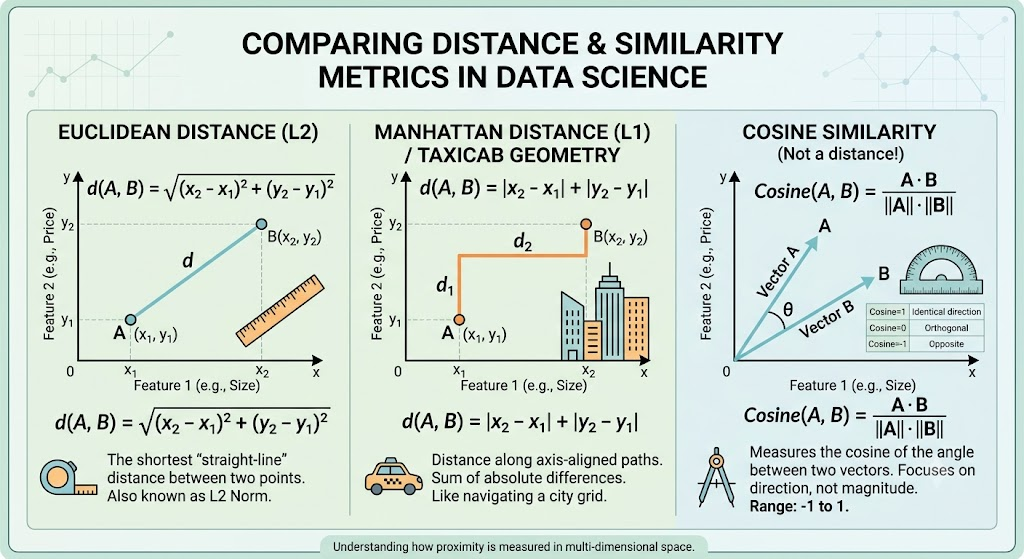

In [2]:
# ── TASK 1 — Implement all three distance metrics ────────────────────────────
# Each function takes two 1D NumPy arrays and returns a float
# Do NOT use scipy.spatial.distance — implement from the formulas above

def euclidean_distance(a: np.ndarray, b: np.ndarray) -> float:
    """Straight-line distance between two vectors."""
    # YOUR CODE HERE
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan_distance(a: np.ndarray, b: np.ndarray) -> float:
    """City-block distance between two vectors."""
    # YOUR CODE HERE
    return np.sum(np.abs(a - b))

def cosine_similarity(a: np.ndarray, b: np.ndarray) -> float:
    """Cosine of the angle between two vectors. Range: -1 to 1."""
    # YOUR CODE HERE
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    if norm_a == 0 or norm_b == 0:
        return 0
    return dot_product / (norm_a * norm_b)

# Sanity checks
A = np.array([2.0, 3.0])
B = np.array([5.0, 7.0])

print(f'Euclidean(A, B)       = {euclidean_distance(A, B):.4f}   (expected: 5.0000)')
print(f'Manhattan(A, B)       = {manhattan_distance(A, B):.4f}   (expected: 7.0000)')
print(f'CosineSim(A, B)       = {cosine_similarity(A, B):.4f}   (expected: ~0.9976)')

# Identical direction test
C = np.array([1.0, 2.0])
D = np.array([10.0, 20.0])  # same direction, 10x bigger
print(f'\nCosineSim([1,2],[10,20]) = {cosine_similarity(C, D):.4f}  (expected: 1.0000 — same direction)')
print(f'Euclidean([1,2],[10,20]) = {euclidean_distance(C, D):.4f}  (expected: large — far apart)')

Euclidean(A, B)       = 5.0000   (expected: 5.0000)
Manhattan(A, B)       = 7.0000   (expected: 7.0000)
CosineSim(A, B)       = 0.9995   (expected: ~0.9976)

CosineSim([1,2],[10,20]) = 1.0000  (expected: 1.0000 — same direction)
Euclidean([1,2],[10,20]) = 20.1246  (expected: large — far apart)


## When Cosine Gives Different Rankings Than Euclidean

Consider this scenario from **text analysis**:

```
Document A (query):   [1, 0, 1]   → mentions "cat" once, "dog" once
Document B:           [2, 0, 2]   → mentions "cat" twice, "dog" twice  (same topic, longer)
Document C:           [1, 1, 0]   → mentions "cat" once, "fish" once   (different topic)
```

Euclidean says B and C are equally far from A.  
Cosine says B is almost identical to A (same direction) and C is clearly different.

For finding **similar documents**, cosine is clearly the right choice.

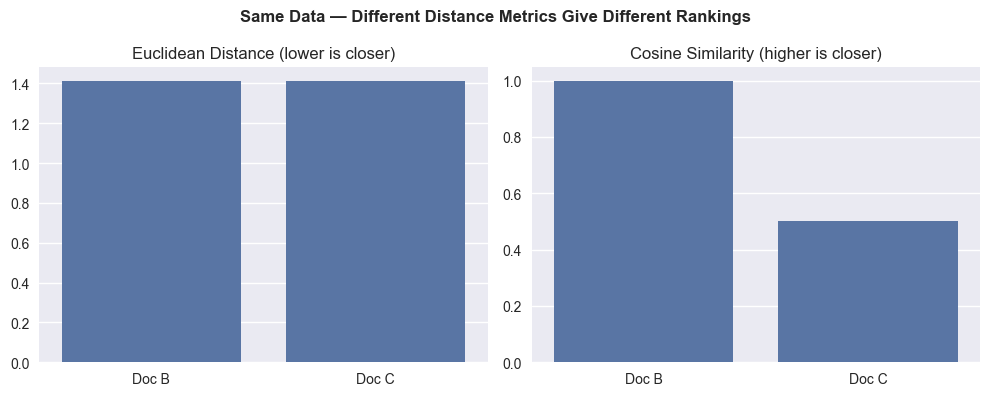

In [3]:
# ── TASK 2 — Compare metric rankings on the text example ─────────────────────
# Given vectors A, B, C below:
# 1. Compute Euclidean distance from A to B, and from A to C
# 2. Compute Cosine similarity from A to B, and from A to C
# 3. Print which document is "closer" to A under each metric
# 4. Create a 2-panel bar chart comparing the two metrics side by side

doc_A = np.array([1.0, 0.0, 1.0])   # query document
doc_B = np.array([2.0, 0.0, 2.0])   # same topic, longer
doc_C = np.array([1.0, 1.0, 0.0])   # different topic

# YOUR CODE HERE — compute distances/similarities
euclidean_AB = euclidean_distance(doc_A, doc_B)
euclidean_AC = euclidean_distance(doc_A, doc_C)
cosine_AB = cosine_similarity(doc_A, doc_B)
cosine_AC = cosine_similarity(doc_A, doc_C)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# YOUR CODE HERE — bar charts
sns.barplot(x=['Doc B', 'Doc C'], y=[euclidean_AB, euclidean_AC], ax=axes[0])
axes[0].set_title('Euclidean Distance (lower is closer)')
sns.barplot(x=['Doc B', 'Doc C'], y=[cosine_AB, cosine_AC], ax=axes[1])
axes[1].set_title('Cosine Similarity (higher is closer)')

plt.suptitle('Same Data — Different Distance Metrics Give Different Rankings',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 Which metric correctly identifies Document B as most similar to A?
# When would you use Euclidean instead of Cosine?
# ...

## Why Feature Scaling is Critical

Distance metrics treat all features equally — they have no idea that "salary" and "age" are on completely different scales.

**Without scaling:**
```
Person A: age=25,  salary=50,000
Person B: age=26,  salary=80,000
Person C: age=50,  salary=51,000

Euclidean(A, B) = √[(26-25)² + (80000-50000)²] ≈ 30,000
Euclidean(A, C) = √[(50-25)² + (51000-50000)²] ≈ 1,000

The algorithm thinks B is 30x farther from A than C is.
But is a 25-year-old with 50k really more similar to a 50-year-old
with 51k than to a 26-year-old with 80k? That depends on context.
```

**Salary completely dominates** the distance calculation simply because it is measured in larger numbers.

**After StandardScaler:** both features have mean=0 and std=1. The algorithm considers them equally.

Distance             A-B Unscaled    A-C Unscaled    A-B Scaled      A-C Scaled     
Euclidean            30000.0000      1000.3125       2.1581          2.1645         


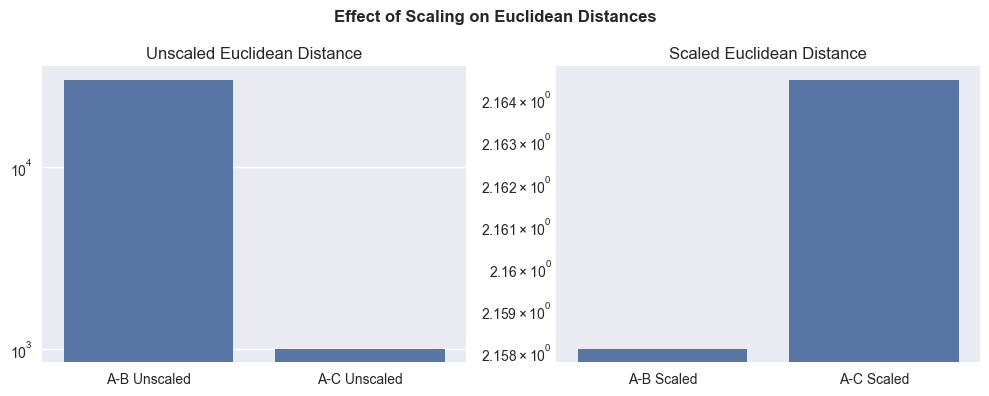

In [4]:
# ── TASK 3 — Demonstrate the scaling effect on distances ─────────────────────
# Use the three people defined below
# 1. Compute Euclidean distance from A to B and A to C WITHOUT scaling
# 2. Apply StandardScaler, recompute the same distances
# 3. Print a comparison table showing distances before and after
# 4. Bar chart: 4 bars (A-B unscaled, A-C unscaled, A-B scaled, A-C scaled)
#    Use log scale on y-axis so both scales are visible

# [age, salary]
person_A = np.array([25.0, 50000.0])
person_B = np.array([26.0, 80000.0])   # similar age, different salary
person_C = np.array([50.0, 51000.0])   # different age, similar salary

people = np.array([person_A, person_B, person_C])

# YOUR CODE HERE
# Compute unscaled distances
euclidean_AB_unscaled = euclidean_distance(person_A, person_B)
euclidean_AC_unscaled = euclidean_distance(person_A, person_C)

# Apply StandardScaler
scaler = StandardScaler()
people_scaled = scaler.fit_transform(people)

# Compute scaled distances
euclidean_AB_scaled = euclidean_distance(people_scaled[0], people_scaled[1])
euclidean_AC_scaled = euclidean_distance(people_scaled[0], people_scaled[2])
# Print comparison table
print(f'{"Distance":<20} {"A-B Unscaled":<15} {"A-C Unscaled":<15} {"A-B Scaled":<15} {"A-C Scaled":<15}')
print(f'{"Euclidean":<20} {euclidean_AB_unscaled:<15.4f} {euclidean_AC_unscaled:<15.4f} {euclidean_AB_scaled:<15.4f} {euclidean_AC_scaled:<15.4f}')

fig,axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x=['A-B Unscaled', 'A-C Unscaled'], y=[euclidean_AB_unscaled, euclidean_AC_unscaled], ax=axes[0])
sns.barplot(x=['A-B Scaled', 'A-C Scaled'], y=[euclidean_AB_scaled, euclidean_AC_scaled], ax=axes[1])
axes[0].set_title('Unscaled Euclidean Distance')
axes[1].set_title('Scaled Euclidean Distance')
axes[0].set_yscale('log')
axes[1].set_yscale('log')
plt.suptitle('Effect of Scaling on Euclidean Distances', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
# 📝 After scaling, which person is closest to A?
# Does this match your intuition about similarity?
# ...

---
# Part 2 — K-Nearest Neighbors

## The Core Idea

KNN is the simplest possible supervised learning algorithm. It has exactly one assumption:

> **"Similar inputs should produce similar outputs."**

When asked to classify a new point, KNN does not compute any formula. It simply:
1. Measures the distance to every training point
2. Finds the K closest ones
3. Returns whatever class the majority of those K neighbors belong to

```
New Point ●

K=5 nearest neighbors:
  🔴 🔴 🔴  ← Class A (3 votes)
  🔵 🔵     ← Class B (2 votes)

Prediction → Class A
```

## Why KNN is Called "Lazy Learning"

Most machine learning algorithms do the hard work at **training time** — they learn a compact representation (weights, rules, centroids) and discard the raw data.

KNN does the opposite:

| | Training | Prediction |
|---|---|---|
| **Logistic Regression** | Slow (optimise weights) | Fast (dot product) |
| **KNN** | Instant (just store data) | Slow (scan all training points) |

For a training set of 1 million points, every single prediction requires computing 1 million distances. That is why KNN does not scale well to very large datasets.



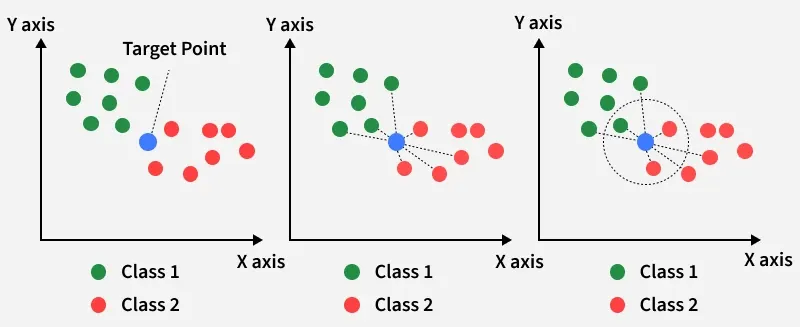

## Implementing KNN from Scratch

Despite being conceptually simple, writing KNN yourself is excellent practice because it forces you to think about:
- How to compute distances between many points efficiently with NumPy
- How to sort and index arrays
- How to take a majority vote

In [5]:
# ── TASK 4 — Implement KNN from scratch ──────────────────────────────────────
# Complete the KNNClassifier class
#
# fit():     just store X_train and y_train
# predict(): for each test point:
#              1. compute Euclidean distance to all training points
#              2. find indices of K smallest distances
#              3. get labels of those K neighbors
#              4. return the most common label (majority vote)
#
# Use your euclidean_distance() function from Task 1

class KNNClassifier:
    def __init__(self, k: int = 3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        # YOUR CODE HERE
        self.X_train = X
        self.y_train = y


    def _predict_single(self, x: np.ndarray) -> int:
        """Predict class for a single test point."""
        # YOUR CODE HERE
        distances = np.array([euclidean_distance(x, x_train) for x_train in self.X_train])
        neighbor_indices = np.argsort(distances)[:self.k]
        neighbor_labels = self.y_train[neighbor_indices]
        most_common = np.bincount(neighbor_labels).argmax()
        return most_common

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Predict classes for all test points."""
        return np.array([self._predict_single(x) for x in X])

print('KNNClassifier defined ✅')

KNNClassifier defined ✅


In [6]:
# ── TASK 5 — Verify scratch KNN against sklearn ───────────────────────────────
# Use the toy dataset below
# 1. Train your KNNClassifier(k=3) on X_train, y_train
# 2. Train sklearn KNeighborsClassifier(n_neighbors=3) on the same data
# 3. Compare predictions on X_test — they should be identical
# 4. Print accuracy for both

from sklearn.datasets import make_classification

X_toy, y_toy = make_classification(
    n_samples=200, n_features=2, n_informative=2,
    n_redundant=0, random_state=42
)
X_toy_train, X_toy_test, y_toy_train, y_toy_test = train_test_split(
    X_toy, y_toy, test_size=0.3, random_state=42
)

# Scale first — distance-based algorithms always need scaling
sc = StandardScaler()
X_toy_train_sc = sc.fit_transform(X_toy_train)
X_toy_test_sc  = sc.transform(X_toy_test)

# YOUR CODE HERE
scratch_knn = KNNClassifier(k=3)
scratch_knn.fit(X_toy_train_sc, y_toy_train)
scratch_preds = scratch_knn.predict(X_toy_test_sc)

print(f'Scratch KNN Accuracy: {accuracy_score(y_toy_test, scratch_preds):.5f}')

# 📝 If predictions differ, what might cause that?
# (Hint: think about how ties in distance are broken)
# ...

Scratch KNN Accuracy: 0.86667


In [7]:
sk_knn = KNeighborsClassifier(n_neighbors=3)
sk_knn.fit(X_toy_train_sc, y_toy_train)
sk_preds = sk_knn.predict(X_toy_test_sc)
print(f'Sklearn KNN Accuracy: {accuracy_score(y_toy_test, sk_preds):.5f}')

Sklearn KNN Accuracy: 0.86667


---
# Part 3 — Choosing K

## The K Tradeoff — Bias vs Variance Again

The choice of K is the single most important hyperparameter in KNN:

```
K = 1
├── Decision boundary: extremely jagged
├── Every training point gets its own "territory"
├── Training accuracy: 100% (always)
└── Effect: OVERFITTING — memorises every point including noise

K = N  (use all training points)
├── Decision boundary: a single horizontal line
├── Always predicts the majority class
├── Training accuracy: just the class balance
└── Effect: UNDERFITTING — ignores all structure

K = √N  (rule of thumb starting point)
└── Usually a reasonable balance
```

**Practical rule:** Always use cross-validation to find the best K. Try odd values (1, 3, 5, 7...) to avoid ties.

/var/folders/1j/qv6pdxz918j7rbrft68hxg_80000gn/T/ipykernel_1364/2422600391.py:47: UserWarning: Legend does not support handles for Annotation instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


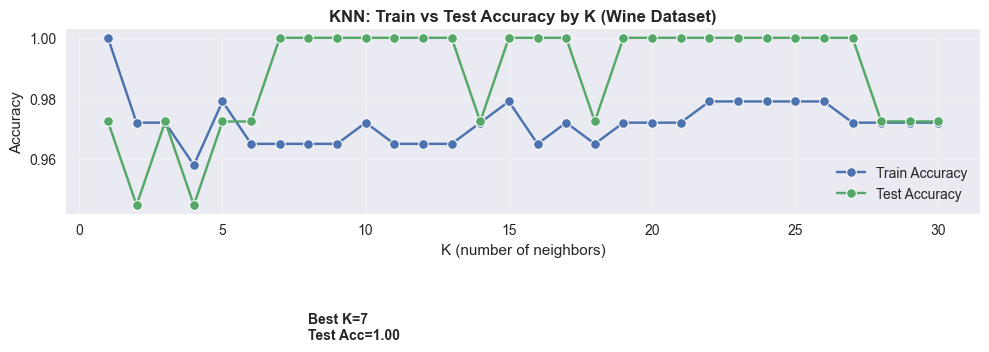

In [8]:
# ── TASK 6 — K sweep: train vs validation accuracy ───────────────────────────
# Load the Wine dataset
# Scale features with StandardScaler
# For K = 1 to 30:
#   - record training accuracy
#   - record test accuracy
# Plot both curves on the same axes
# Mark the K with best test accuracy

wine = load_wine()
X_wine, y_wine = wine.data, wine.target

X_w_train, X_w_test, y_w_train, y_w_test = train_test_split(
    X_wine, y_wine, test_size=0.2, stratify=y_wine, random_state=42
)

sc_wine = StandardScaler()
X_w_train_sc = sc_wine.fit_transform(X_w_train)
X_w_test_sc  = sc_wine.transform(X_w_test)

k_values   = range(1, 31)
train_accs = []
test_accs  = []

# YOUR CODE HERE
for k in k_values:
    knn = KNNClassifier(k=k)
    knn.fit(X_w_train_sc, y_w_train)
    train_preds = knn.predict(X_w_train_sc)
    test_preds = knn.predict(X_w_test_sc)
    train_accs.append(accuracy_score(y_w_train, train_preds))
    test_accs.append(accuracy_score(y_w_test, test_preds))

fig, ax = plt.subplots(figsize=(10, 5))
# YOUR CODE HERE — plot curves and mark best K
sns.lineplot(x=k_values, y=train_accs, marker='o', label='Train Accuracy', ax=ax)
sns.lineplot(x=k_values, y=test_accs, marker='o', label='Test Accuracy', ax=ax)
best_k = k_values[np.argmax(test_accs)]
best_test_acc = max(test_accs)
ax.annotate(f'Best K={best_k}\nTest Acc={best_test_acc:.2f}', xy=(best_k, best_test_acc), xytext=(best_k+1, best_test_acc-0.1),
            label=dict(facecolor='black', shrink=0.05), fontsize=10, fontweight='bold')


ax.set_title('KNN: Train vs Test Accuracy by K (Wine Dataset)', fontweight='bold')
ax.set_xlabel('K (number of neighbors)')
ax.set_ylabel('Accuracy')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 📝 At K=1 the training accuracy is always 1.0 — why?
# ...

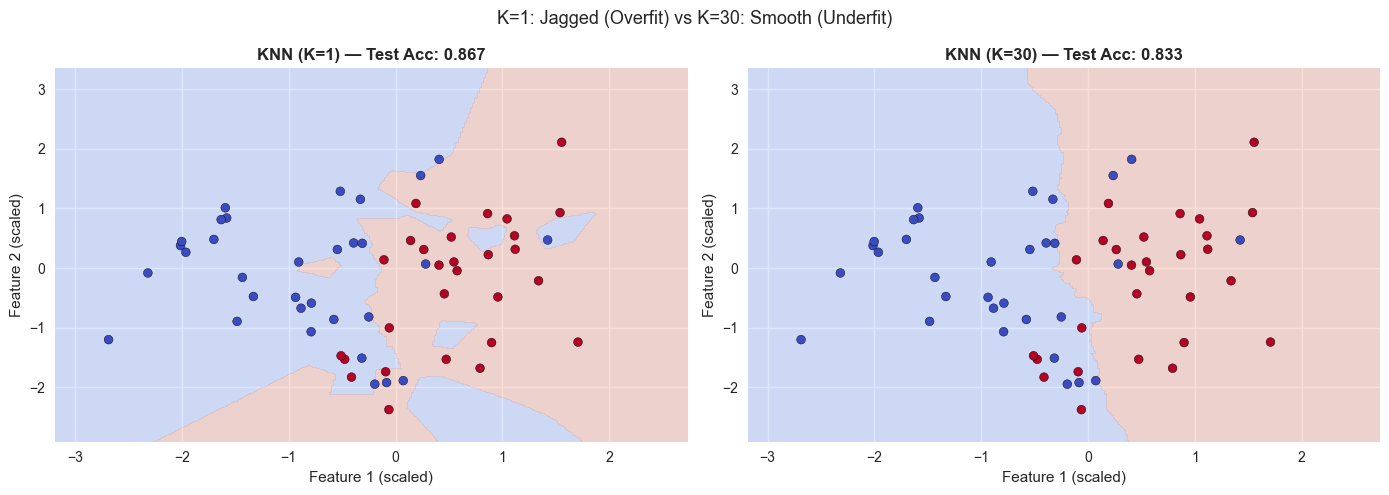

In [9]:
# ── TASK 7 — Decision boundary: K=1 vs K=30 ─────────────────────────────────
# Use the 2-feature toy dataset from Task 5 (already split and scaled)
# Create 1×2 subplot:
#   Left:  decision boundary for KNeighborsClassifier(k=1)
#   Right: decision boundary for KNeighborsClassifier(k=30)
#
# For each: create a meshgrid, predict for every point, plot filled contours
# Then scatter the actual test points coloured by true label on top
# Title each plot with its accuracy on test data

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# determine grid bounds from training+test scaled data
all_X = np.vstack([X_toy_train_sc, X_toy_test_sc])
x_min, x_max = all_X[:, 0].min() - 0.5, all_X[:, 0].max() + 0.5
y_min, y_max = all_X[:, 1].min() - 0.5, all_X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

for ax, k in zip(axes, [1, 30]):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_toy_train_sc, y_toy_train)
    acc = knn.score(X_toy_test_sc, y_toy_test)

    Z = knn.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm', levels=np.arange(Z.max()+2)-0.5)
    sc = ax.scatter(X_toy_test_sc[:, 0], X_toy_test_sc[:, 1],
                    c=y_toy_test, cmap='coolwarm', edgecolor='k', s=40)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_title(f'KNN (K={k}) — Test Acc: {acc:.3f}', fontweight='bold')
    ax.set_xlabel('Feature 1 (scaled)')
    ax.set_ylabel('Feature 2 (scaled)')

plt.suptitle('K=1: Jagged (Overfit) vs K=30: Smooth (Underfit)', fontsize=13)
plt.tight_layout()
plt.show()

# 📝 Describe the shape of each boundary in one sentence.
# ...

---
# Part 4 — Scaling Impact Demo

## The Proof is in the Numbers

You have seen the theory — now measure the actual performance difference.

The Wine dataset has 13 features with very different scales:

| Feature | Typical Range |
|---------|---------------|
| Alcohol | 11–15 |
| Malic acid | 0.7–5.8 |
| Proline | 278–1680 |
| Magnesium | 70–162 |

**Proline** ranges up to 1680. **Malic acid** goes up to 5.8.  
Without scaling, Proline completely dominates every distance calculation.  
The other 12 features become nearly invisible to KNN.

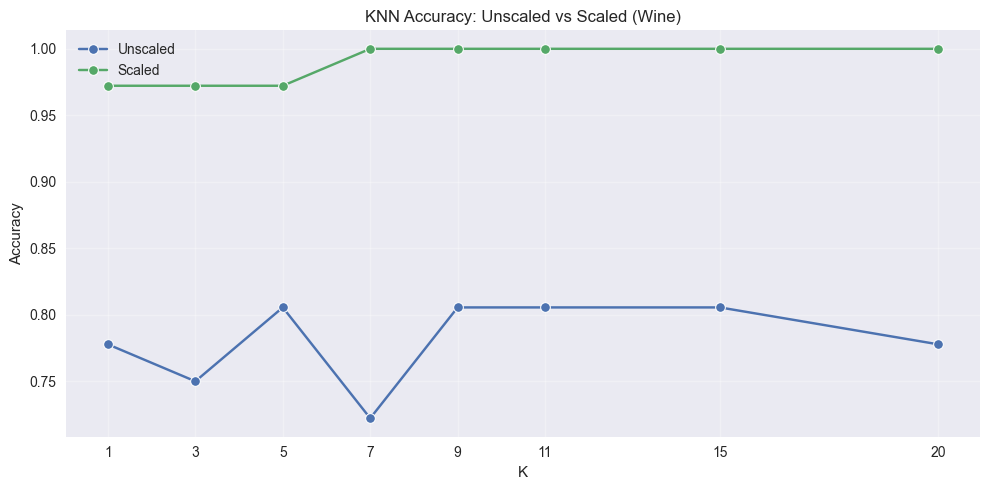

Best Unscaled: K=5  Acc=0.8056
Best  Scaled: K=7  Acc=1.0000
Accuracy improvement (scaled - unscaled): 0.1944


In [10]:
# ── TASK 8 — KNN accuracy: with scaling vs without ───────────────────────────
# Use the Wine dataset (already loaded above)
# Test K values = [1, 3, 5, 7, 9, 11, 15, 20]
#
# For each K:
#   - train KNN on RAW (unscaled) features → record accuracy
#   - train KNN on SCALED features → record accuracy
#
# Plot both lines on the same axes
# Also print the best accuracy for each approach and the improvement
k_vals = [1, 3, 5, 7, 9, 11, 15, 20]
raw_accs = []
scaled_accs = []

for k in k_vals:
    knn_raw = KNeighborsClassifier(n_neighbors=k)
    knn_raw.fit(X_w_train, y_w_train)
    raw_accs.append(accuracy_score(y_w_test, knn_raw.predict(X_w_test)))

    knn_sc = KNeighborsClassifier(n_neighbors=k)
    knn_sc.fit(X_w_train_sc, y_w_train)
    scaled_accs.append(accuracy_score(y_w_test, knn_sc.predict(X_w_test_sc)))

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=k_vals, y=raw_accs, marker='o', label='Unscaled', ax=ax)
sns.lineplot(x=k_vals, y=scaled_accs, marker='o', label='Scaled', ax=ax)
ax.set_xlabel('K')
ax.set_ylabel('Accuracy')
ax.set_title('KNN Accuracy: Unscaled vs Scaled (Wine)')
ax.set_xticks(k_vals)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_raw_idx = int(np.argmax(raw_accs))
best_sc_idx = int(np.argmax(scaled_accs))
best_raw_k, best_raw_acc = k_vals[best_raw_idx], raw_accs[best_raw_idx]
best_sc_k, best_sc_acc = k_vals[best_sc_idx], scaled_accs[best_sc_idx]

print(f'Best Unscaled: K={best_raw_k}  Acc={best_raw_acc:.4f}')
print(f'Best  Scaled: K={best_sc_k}  Acc={best_sc_acc:.4f}')
print(f'Accuracy improvement (scaled - unscaled): {best_sc_acc - best_raw_acc:.4f}')


# 📝 How large is the accuracy gap? Which feature do you think dominated
# the unscaled distances? (Hint: check wine.feature_names and the ranges above)
# ...

---
# Part 5 — Support Vector Machines

## The Core Idea — Maximum Margin

KNN draws its decision boundary wherever the neighborhood votes change. It has no concept of confidence.

SVM takes a completely different philosophy:

> **"Find the boundary that is as far as possible from ALL training points."**

```
                    ← Margin →
  ● ● ●   |  - - - | - - - |  ■ ■ ■
  ● ● ●   |  - - - | - - - |  ■ ■ ■
           Support  Decision  Support
           Vectors  Boundary  Vectors
```

The boundary sits exactly in the **middle of the widest possible gap** between the two classes.

## Support Vectors — The Key Concept

**Support vectors** are the training points that sit on the edges of the margin — the points closest to the boundary.

Here is the remarkable thing: **only support vectors determine the final boundary**.

You could remove every other training point and the model would not change at all. This makes SVM very robust — it is not influenced by the bulk of the data, only by the points near the boundary.

## Soft Margin SVM — Parameter C

Real data is almost never perfectly separable. SVM handles this with a **soft margin** — it allows some points to be on the wrong side of the boundary, but penalises them.

The parameter **C** controls this trade-off:

```
Large C  →  "I cannot tolerate misclassifications"
          →  Narrow margin, fits training data tightly
          →  Risk of overfitting

Small C  →  "I accept some misclassifications for a wider margin"
          →  Wide margin, more generalisation
          →  Risk of underfitting if too small
```

Think of C as **how strict the teacher is** — very strict (large C) means zero mistakes allowed but the rules become very specific to this class. More lenient (small C) means some mistakes are okay but the rules generalise better.

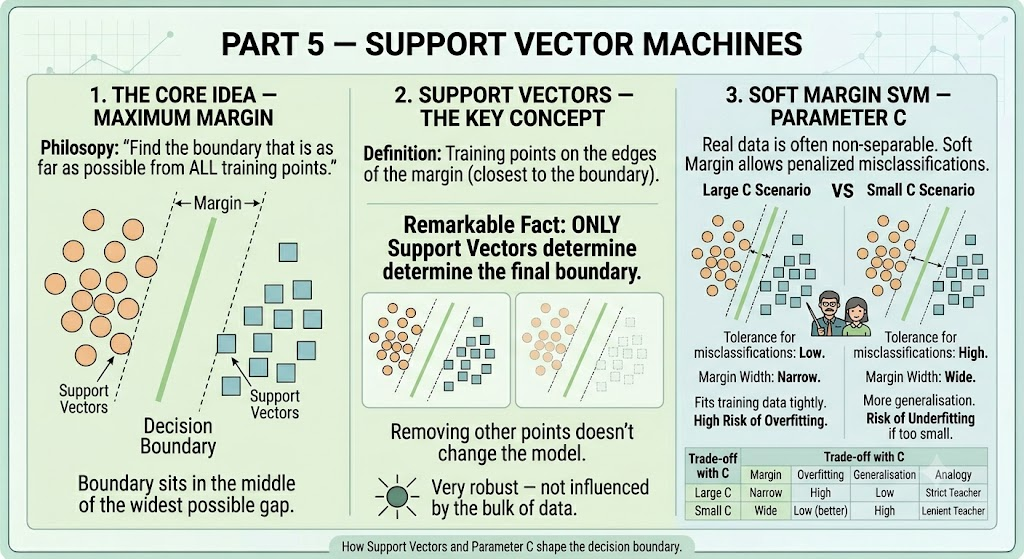

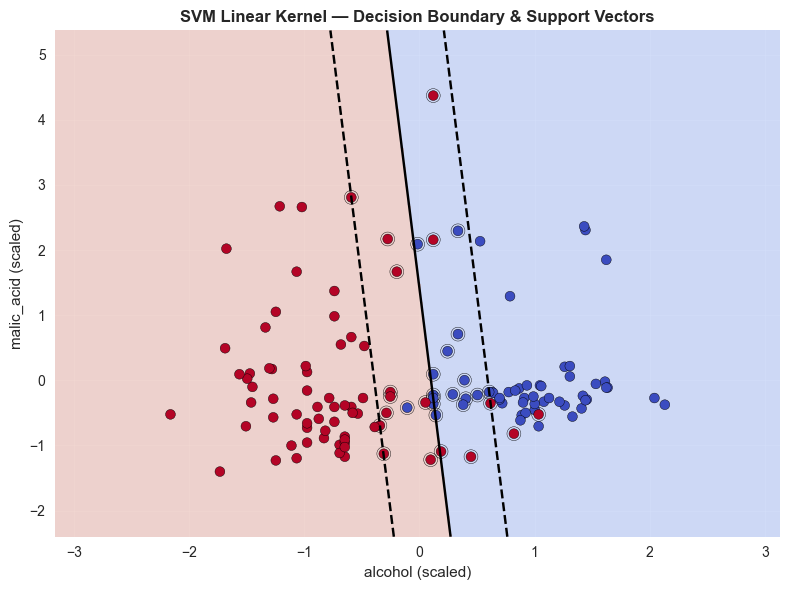

Number of support vectors: [16 17]


In [11]:
# ── TASK 9 — SVM linear: boundary + support vectors ──────────────────────────
# Use a 2-feature binary dataset (first 2 features of Wine, classes 0 and 1 only)
# 1. Train SVC(kernel='linear', C=1.0)
# 2. Plot the decision boundary (meshgrid + contourf)
# 3. Plot the margin boundaries (contour at levels -1 and +1 using decision_function)
# 4. Highlight the support vectors with a large circle marker (ax.scatter with
#    model.support_vectors_)
# 5. Scatter the training points coloured by class

# Prepare 2-class, 2-feature dataset
mask = y_wine < 2
X_svm2 = X_wine[mask][:, :2]   # first two features only
y_svm2 = y_wine[mask]

sc_svm = StandardScaler()
X_svm2_sc = sc_svm.fit_transform(X_svm2)

svm_lin = SVC(kernel='linear', C=1.0)
svm_lin.fit(X_svm2_sc, y_svm2)

fig, ax = plt.subplots(figsize=(8, 6))
# YOUR CODE HERE — boundary, margins, support vectors, scatter
# Create meshgrid
x_min, x_max = X_svm2_sc[:, 0].min() - 1, X_svm2_sc[:, 0].max() + 1
y_min, y_max = X_svm2_sc[:, 1].min() - 1, X_svm2_sc[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = svm_lin.predict(grid).reshape(xx.shape)
ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm', levels=np.arange(Z.max()+2)-0.5)
# Margins
decision_values = svm_lin.decision_function(grid).reshape(xx.shape)
ax.contour(xx, yy, decision_values, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
# Support vectors

#show support vector count in title
ax.set_title(f'SVM Linear Kernel — Decision Boundary & Support Vectors\n(Number of support vectors: {svm_lin.n_support_[0]} class 0, {svm_lin.n_support_[1]} class 1)')
ax.scatter(svm_lin.support_vectors_[:, 0], svm_lin.support_vectors_[:, 1],
           s=100, facecolors='none', edgecolors='k', label='Support Vectors')
# Training points
scatter = ax.scatter(X_svm2_sc[:, 0], X_svm2_sc[:, 1], c=y_svm2, cmap='coolwarm', edgecolor='k', s=50, label='Training Points') 




ax.set_title('SVM Linear Kernel — Decision Boundary & Support Vectors',
             fontweight='bold')
ax.set_xlabel(f'{wine.feature_names[0]} (scaled)')
ax.set_ylabel(f'{wine.feature_names[1]} (scaled)')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f'Number of support vectors: {svm_lin.n_support_}')

# 📝 How many support vectors does each class have?
# What happens to the number of support vectors if you increase C?
# ...

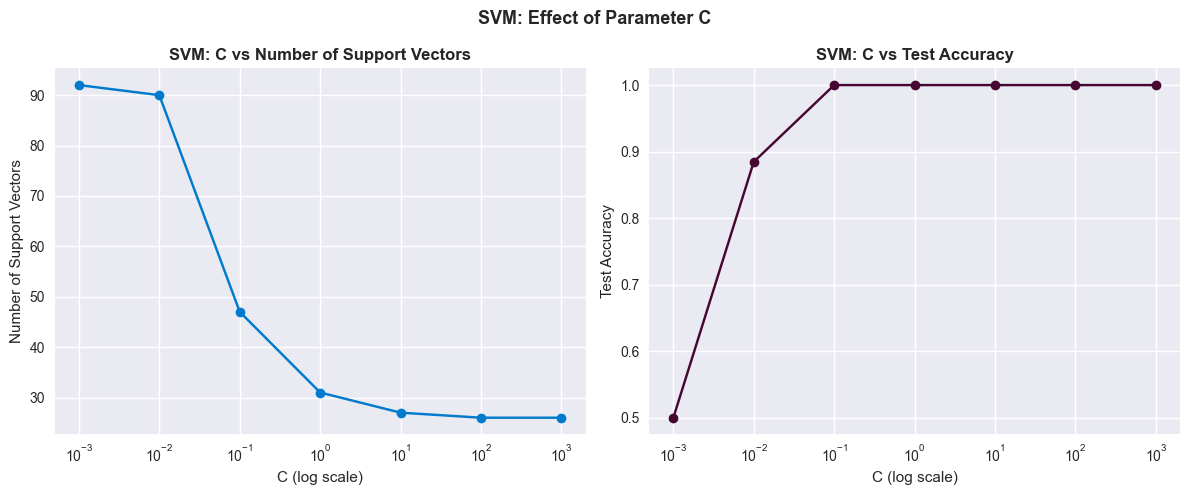

In [12]:
# ── TASK 10 — C parameter sweep ──────────────────────────────────────────────
# Train SVC(kernel='linear') for each C in c_values
# For each C, record:
#   - number of support vectors (sum of model.n_support_)
#   - test accuracy
# Create 1×2 subplot:
#   Left:  C vs number of support vectors
#   Right: C vs test accuracy
# Use log scale on x-axis for both

X_sv_tr, X_sv_te, y_sv_tr, y_sv_te = train_test_split(
    X_svm2_sc, y_svm2, test_size=0.2, random_state=42
)

c_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
n_sv_list  = []
c_accs     = []

# YOUR CODE HERE
for c in c_values:
    svm = SVC(kernel='linear', C=c)
    svm.fit(X_sv_tr, y_sv_tr)
    n_sv_list.append(svm.n_support_.sum())
    c_accs.append(svm.score(X_sv_te, y_sv_te))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# YOUR CODE HERE — plots
axes[0].plot(c_values, n_sv_list, marker='o',color='#007acc')
axes[0].set_xscale('log')
axes[0].set_xlabel('C (log scale)')
axes[0].set_ylabel('Number of Support Vectors')
axes[0].set_title('SVM: C vs Number of Support Vectors', fontweight='bold')
axes[1].plot(c_values, c_accs, marker='o',color="#450731")
axes[1].set_xscale('log')
axes[1].set_xlabel('C (log scale)')
axes[1].set_ylabel('Test Accuracy')
axes[1].set_title('SVM: C vs Test Accuracy', fontweight='bold')


plt.suptitle('SVM: Effect of Parameter C', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 As C increases, what happens to the number of support vectors?
# What does fewer support vectors mean for the margin width?
# ...

---
# Part 6 — The Kernel Trick & RBF Kernel

## When a Line is Not Enough

Consider this data:

```
        🔵 🔵 🔵
    🔴 🔴  🔵  🔴 🔴
  🔴 🔴 🔴  🔵  🔴 🔴 🔴
    🔴 🔴  🔵  🔴 🔴
        🔵 🔵 🔵
```

Blue is inside a ring, red is outside. No straight line can separate them. Linear SVM fails completely.

## The Kernel Trick

**Idea:** Map the data into a higher-dimensional space where it *is* linearly separable, draw the boundary there, then map back.

```
2D (not separable)
      ↓  kernel transform
3D (separable with a flat plane)
      ↓  find optimal hyperplane
2D (curved boundary in original space)
```

The genius of the kernel trick: you never actually have to compute the high-dimensional coordinates. The kernel function computes the **dot product in that space** directly from the original coordinates.

## RBF (Radial Basis Function) Kernel

$$K(x, z) = e^{-\gamma \|x - z\|^2}$$

This measures similarity based on distance. Points that are close together get a high kernel value. Points far apart get a value near zero.

### The Gamma Parameter

```
Small γ  →  each point influences a WIDE neighbourhood
           →  smooth, simple decision boundary
           →  may underfit

Large γ  →  each point influences only VERY nearby points
           →  wiggly, complex boundary that wraps tightly around training data
           →  may overfit
```

Think of γ as the **"memory"** of each support vector — how far does its influence reach?

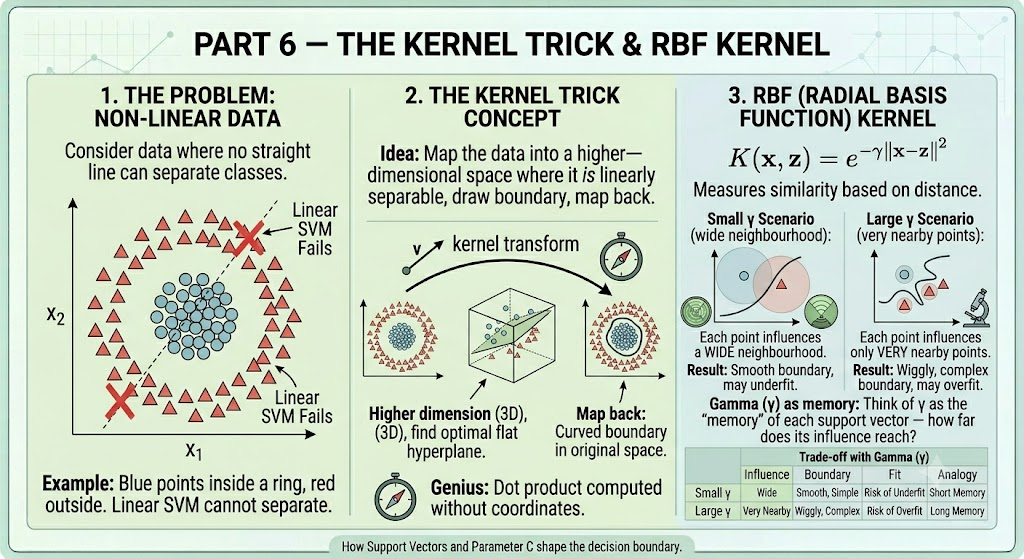

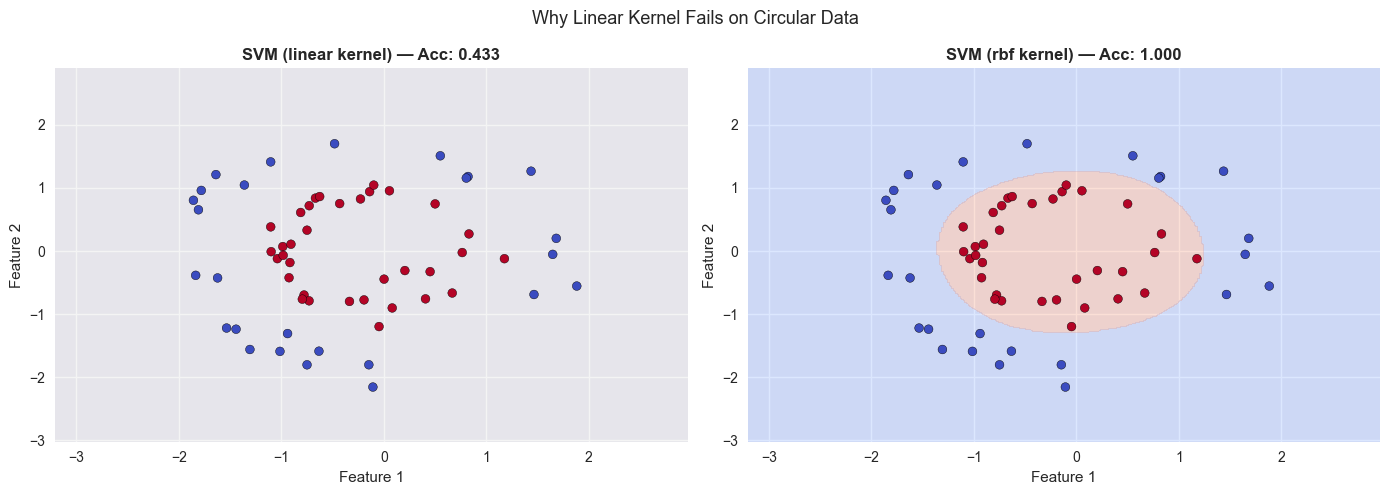

In [13]:
# ── TASK 11 — Linear vs RBF on circular data ─────────────────────────────────
# Generate circular (non-linearly separable) data with make_circles
# Create 1×2 subplot:
#   Left:  SVC(kernel='linear') decision boundary
#   Right: SVC(kernel='rbf', gamma='scale') decision boundary
# Use meshgrid + contourf for each
# Print accuracy for each

X_circ, y_circ = make_circles(n_samples=300, noise=0.1, factor=0.5, random_state=42)
X_circ_tr, X_circ_te, y_circ_tr, y_circ_te = train_test_split(
    X_circ, y_circ, test_size=0.2, random_state=42
)

# Note: make_circles data is already on a similar scale — scaling still recommended
sc_c = StandardScaler()
X_circ_tr_sc = sc_c.fit_transform(X_circ_tr)
X_circ_te_sc = sc_c.transform(X_circ_te)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (kernel, gamma) in zip(axes,
                               [('linear', 'scale'), ('rbf', 'scale')]):
    svm = SVC(kernel=kernel, gamma=gamma, C=1.0)
    svm.fit(X_circ_tr_sc, y_circ_tr)
    acc = svm.score(X_circ_te_sc, y_circ_te)

    # YOUR CODE HERE — meshgrid, contourf, scatter
    x_min, x_max = X_circ_tr_sc[:, 0].min() - 1, X_circ_tr_sc[:, 0].max() + 1
    y_min, y_max = X_circ_tr_sc[:, 1].min() - 1, X_circ_tr_sc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = svm.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm', levels=np.arange(Z.max()+2)-0.5)
    ax.scatter(X_circ_te_sc[:, 0], X_circ_te_sc[:, 1], c=y_circ_te, cmap='coolwarm', edgecolor='k', s=40)

    ax.set_title(f'SVM ({kernel} kernel) — Acc: {acc:.3f}', fontweight='bold')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')

plt.suptitle('Why Linear Kernel Fails on Circular Data', fontsize=13)
plt.tight_layout()
plt.show()

# 📝 What is the linear kernel's accuracy? What does this tell you about its
# ability to solve this problem?
# ...

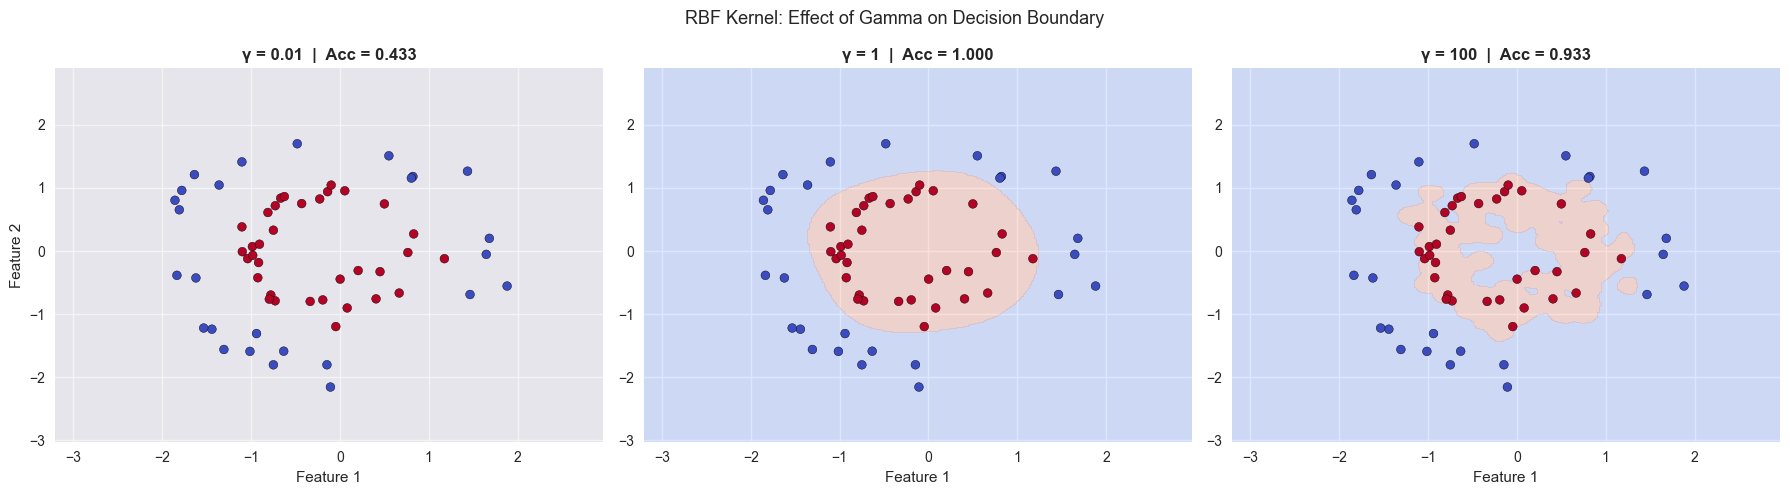

In [14]:
# ── TASK 12 — Gamma sweep: smooth to overfit ─────────────────────────────────
# Train SVC(kernel='rbf') with gamma = 0.01, 1, 100 on the circular data
# Plot all three decision boundaries in a 1×3 grid
# Title each with its gamma value and test accuracy
# Observe how the boundary changes from smooth → complex → overfit

gammas = [0.01, 1, 100]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, gamma in zip(axes, gammas):
    svm = SVC(kernel='rbf', gamma=gamma, C=1.0)
    svm.fit(X_circ_tr_sc, y_circ_tr)
    acc = svm.score(X_circ_te_sc, y_circ_te)

    # YOUR CODE HERE — meshgrid, contourf, scatter
    x_min, x_max = X_circ_tr_sc[:, 0].min() - 1, X_circ_tr_sc[:, 0].max() + 1
    y_min, y_max = X_circ_tr_sc[:, 1].min() - 1, X_circ_tr_sc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = svm.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm', levels=np.arange(Z.max()+2)-0.5)
    ax.scatter(X_circ_te_sc[:, 0], X_circ_te_sc[:, 1], c=y_circ_te, cmap='coolwarm', edgecolor='k', s=40)

    ax.set_title(f'γ = {gamma}  |  Acc = {acc:.3f}', fontweight='bold')
    ax.set_xlabel('Feature 1')

axes[0].set_ylabel('Feature 2')
plt.suptitle('RBF Kernel: Effect of Gamma on Decision Boundary', fontsize=13)
plt.tight_layout()
plt.show()

# 📝 At gamma=100, describe the shape of the boundary.
# Is this overfitting? How can you tell?
# ...

---
# Part 7 — K-Means Clustering

## A Different Kind of Learning — Unsupervised

Everything we have done so far has been **supervised** — we had labels (class 0, class 1) and the algorithm learned to predict them.

**Clustering is unsupervised** — there are no labels. The algorithm has to discover structure in the data on its own.

**Real-world use cases:**
- Customer segmentation: group customers by behaviour without knowing groups in advance
- Document clustering: group news articles by topic automatically
- Anomaly detection: points that don't belong to any cluster may be anomalies
- Image compression: replace many similar colours with a single representative colour

## How K-Means Works

```
Step 1:  Choose K random points as initial centroids
         ● ● ●  ← 3 random centroids

Step 2:  Assign each data point to nearest centroid
         Every point: "who am I closest to?"

Step 3:  Move each centroid to the mean of its assigned points
         Centroid slides to the centre of its cluster

Step 4:  Repeat steps 2 and 3 until nothing changes
         (convergence)
```

## The Objective Function — WCSS

K-Means minimises **Within-Cluster Sum of Squares (WCSS)**:

$$\text{WCSS} = \sum_{k=1}^{K} \sum_{x \in C_k} \|x - \mu_k\|^2$$

where $\mu_k$ is the centroid of cluster $k$.

Lower WCSS = tighter, more compact clusters = better.

## K-Means Limitations — Know These

| Limitation | Why it matters |
|------------|----------------|
| Must specify K in advance | You don't always know how many clusters exist |
| Sensitive to initialisation | Different random starts can give different results |
| Assumes spherical clusters | Struggles with elongated or irregular shapes |
| Sensitive to outliers | One outlier can pull a centroid far from its cluster |

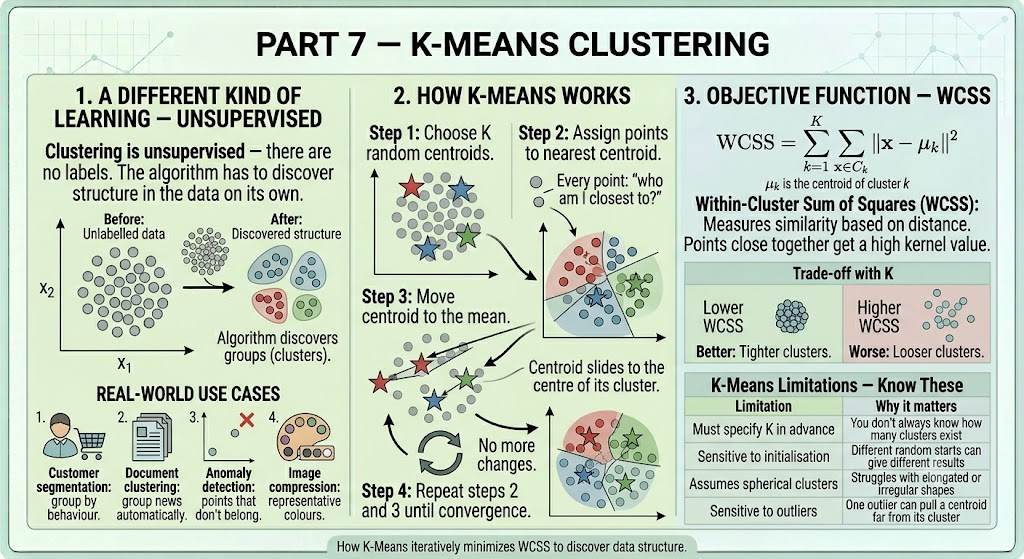

In [15]:
# ── TASK 13 — Implement K-Means from scratch ─────────────────────────────────
# Complete the KMeansScratch class below
#
# fit() should:
#   1. Randomly initialise K centroids by picking K random data points
#   2. Repeat until convergence (or max_iters):
#        a. Assign each point to the nearest centroid
#           (use Euclidean distance to each centroid)
#        b. Recompute each centroid as the mean of its assigned points
#        c. If centroids did not change → stop
#   3. Store final cluster labels in self.labels_
#   4. Store final centroids in self.centroids_
#   5. Compute WCSS and store in self.inertia_

class KMeansScratch:
    def __init__(self, k: int = 3, max_iters: int = 100, random_state: int = 42):
        self.k = k
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids_ = None
        self.labels_     = None
        self.inertia_    = None

    def fit(self, X: np.ndarray):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape
        # Step 1: Randomly initialise centroids by picking K random data points
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids_ = X[random_indices]
        # idxs = np.random.choice(n_samples, self.k, replace=False)
        # self.centroids_ = X[idxs]

    def _assign_clusters(self, X: np.ndarray) -> np.ndarray:
        """Assign each point to the nearest centroid."""
        # YOUR CODE HERE
        distances = np.array([[euclidean_distance(x, centroid) for centroid in self.centroids_] for x in X])
        return np.argmin(distances, axis=1)

    def _compute_centroids(self, X: np.ndarray, labels: np.ndarray) -> np.ndarray:
        """Compute new centroids as mean of assigned points."""
        # YOUR CODE HERE
        new_centroids = []
        for i in range(self.k):
            cluster_points = X[labels == i]
            new_centroids.append(cluster_points.mean(axis=0))
        return np.array(new_centroids)

print('KMeansScratch defined ✅')

KMeansScratch defined ✅


/var/folders/1j/qv6pdxz918j7rbrft68hxg_80000gn/T/ipykernel_1364/3800457622.py:16: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=kmeans_scratch.labels_, cmap='viridis', edgecolor='k', s=50)


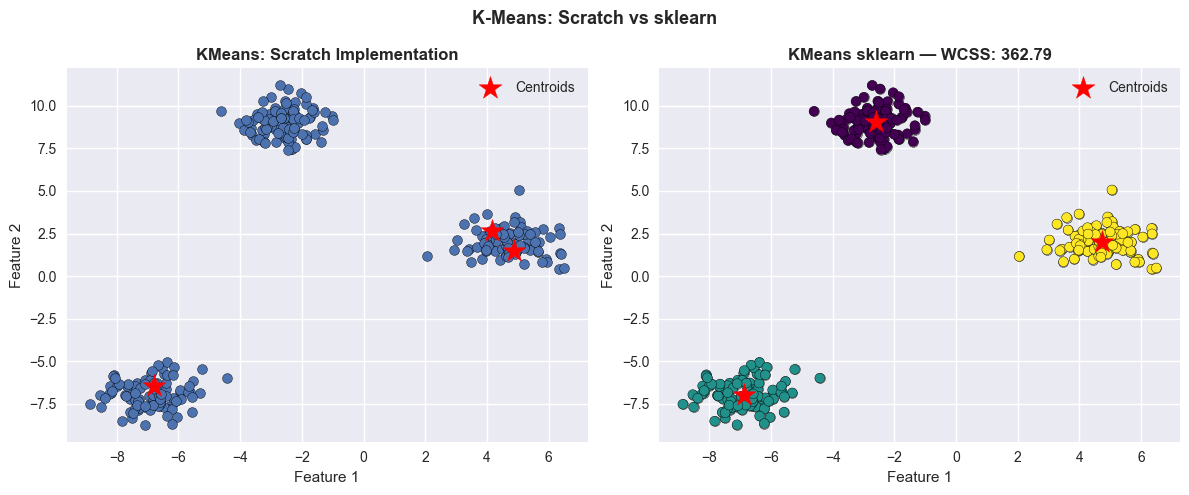

In [16]:
# ── TASK 14 — Verify scratch K-Means against sklearn ─────────────────────────
# Generate toy clustering data with make_blobs (3 clusters)
# Run both KMeansScratch(k=3) and sklearn KMeans(n_clusters=3) on the same data
# Plot side-by-side: scratch (left), sklearn (right)
# Mark centroids with a star marker (marker='*', s=300)
# Print WCSS for both — they should be close

from sklearn.datasets import make_blobs
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.8, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# YOUR CODE HERE
kmeans_scratch = KMeansScratch(k=3, random_state=42)
kmeans_scratch.fit(X_blobs)
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=kmeans_scratch.labels_, cmap='viridis', edgecolor='k', s=50)
axes[0].scatter(kmeans_scratch.centroids_[:, 0], kmeans_scratch.centroids_[:, 1], marker='*', s=300, color='red', label='Centroids')
# # axes[0].set_title(f'KMeans Scratch — WCSS: {kmeans_scratch.inertia_:.2f}', fontweight='bold')
axes[0].legend()
axes[0].set_title('KMeans: Scratch Implementation', fontweight='bold')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')

axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c='lightgray', edgecolor='k', s=50)
sk_kmeans = KMeans(n_clusters=3, random_state=42)
sk_kmeans.fit(X_blobs)
axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=sk_kmeans.labels_, cmap='viridis', edgecolor='k', s=50)
axes[1].scatter(sk_kmeans.cluster_centers_[:, 0], sk_kmeans.cluster_centers_[:, 1], marker='*', s=300, color='red', label='Centroids')
axes[1].set_title(f'KMeans sklearn — WCSS: {sk_kmeans.inertia_:.2f}', fontweight='bold')
axes[1].legend()
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
plt.suptitle('K-Means: Scratch vs sklearn', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 Are the cluster assignments identical between scratch and sklearn?
# If not, why might they differ?
# (Hint: cluster labels are arbitrary — cluster 0 in one run may be cluster 2 in another)
# ...

---
# Part 8 — The Elbow Method

## How Do You Choose K?

This is the fundamental challenge of K-Means. Unlike supervised learning where you can measure accuracy against true labels, clustering has no ground truth to validate against.

The **Elbow Method** uses WCSS as a proxy:

```
WCSS always decreases as K increases
(more clusters → each cluster is smaller → tighter)

At K=N (one cluster per point): WCSS = 0
But that is useless — every point is its own cluster

The "elbow" is where the rate of decrease sharply slows down:

WCSS
│
│\              ← steep drop (each new cluster adds real value)
│ \
│  \
│   \_________  ← plateau (diminishing returns)
│
└─────────────── K
   1 2 3 4 5 6
         ↑
       elbow = optimal K
```

**Limitation:** The elbow is sometimes not obvious. When in doubt, also consider domain knowledge — "how many customer segments make business sense?"

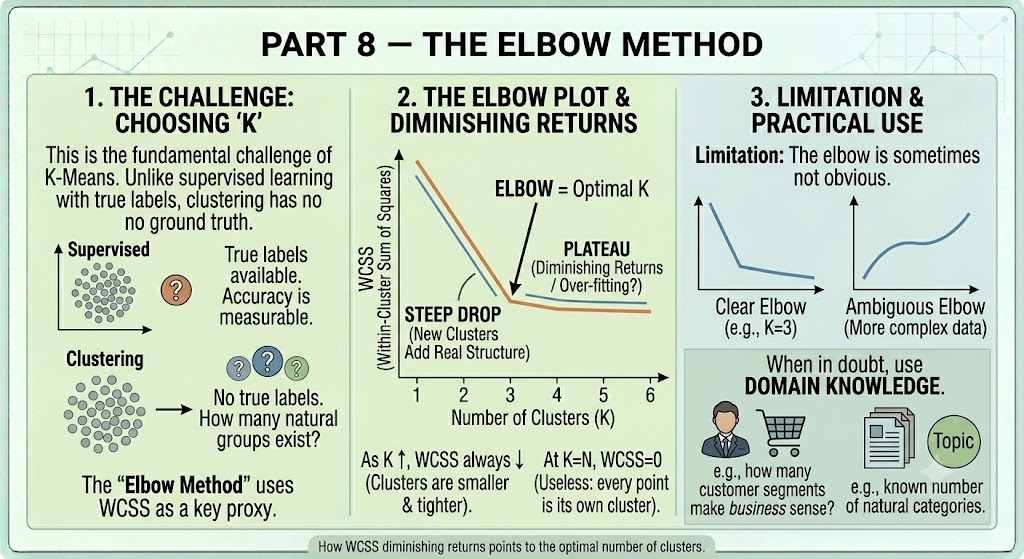

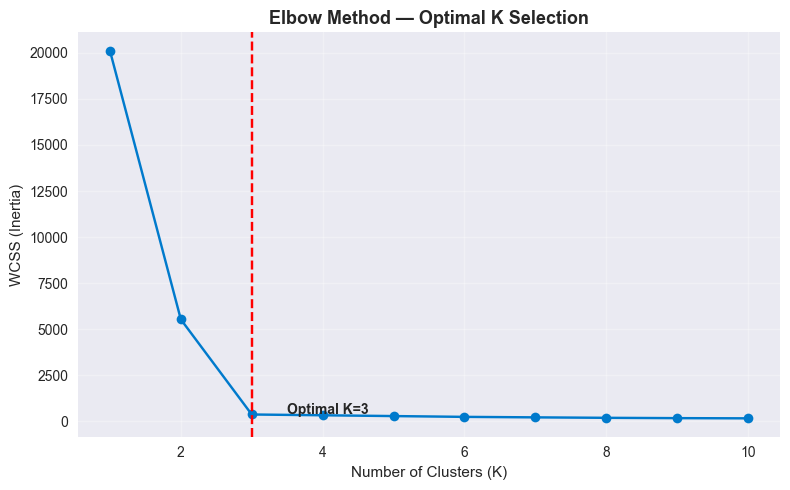

In [17]:
# ── TASK 15 — Elbow Method ───────────────────────────────────────────────────
# Run KMeans for K = 1 to 10 on X_blobs
# Collect WCSS (model.inertia_) for each K
# Plot the elbow curve
# Mark the optimal K with a vertical dashed line and annotation

k_range = range(1, 11)
wcss_vals = []

# YOUR CODE HERE
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_blobs)
    wcss_vals.append(kmeans.inertia_)

fig, ax = plt.subplots(figsize=(8, 5))
# YOUR CODE HERE — plot elbow curve
ax.plot(k_range, wcss_vals, marker='o', color='#007acc')
optimal_k = 3
ax.axvline(optimal_k, color='red', linestyle='--')
ax.annotate(f'Optimal K={optimal_k}', xy=(optimal_k, wcss_vals[optimal_k-1]), xytext=(optimal_k+0.5, wcss_vals[optimal_k-1]+10),
            label=dict(facecolor='black', shrink=0.05), fontsize=10, fontweight='bold')    




ax.set_title('Elbow Method — Optimal K Selection', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('WCSS (Inertia)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 📝 What K does the elbow suggest? Does that match the actual number of
# clusters we used when generating the data (n_centers=3)?
# ...

---
# 🛍️ Lab 1 — Mall Customers: Customer Segmentation

## Business Context

A shopping mall has collected data on 200 customers: their annual income and how much they spend in the mall (spending score 1–100).

**Goal:** Discover natural customer segments without any predefined labels.

**Why this matters:** Each segment may respond differently to marketing. High income + high spending = loyal customers to reward. High income + low spending = customers to convert. Low income + high spending = budget-conscious enthusiasts.

**Features we will use:**
- `Annual Income (k$)` — customer's yearly income
- `Spending Score (1–100)` — mall-assigned score based on purchase behaviour

Shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6


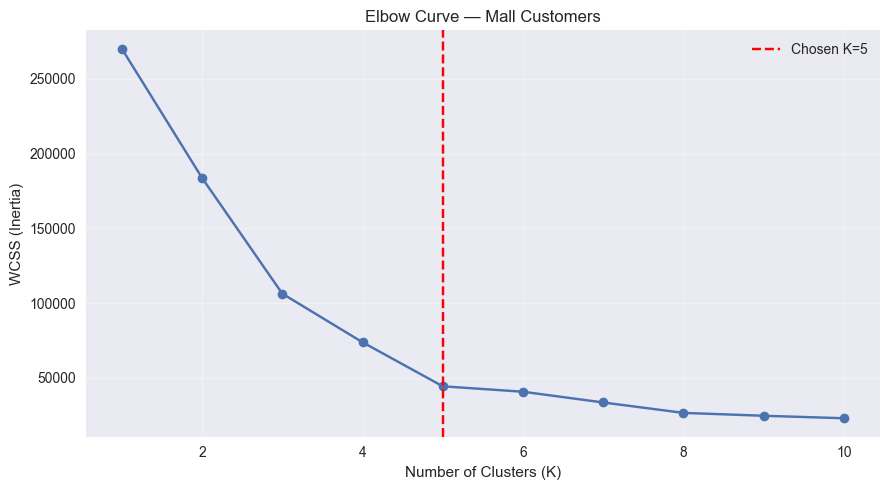

K=1  WCSS=269981.28
K=2  WCSS=183653.33
K=3  WCSS=106348.37
K=4  WCSS=73880.64
K=5  WCSS=44448.46
K=6  WCSS=40825.17
K=7  WCSS=33642.58
K=8  WCSS=26686.84
K=9  WCSS=24766.47
K=10  WCSS=23103.12


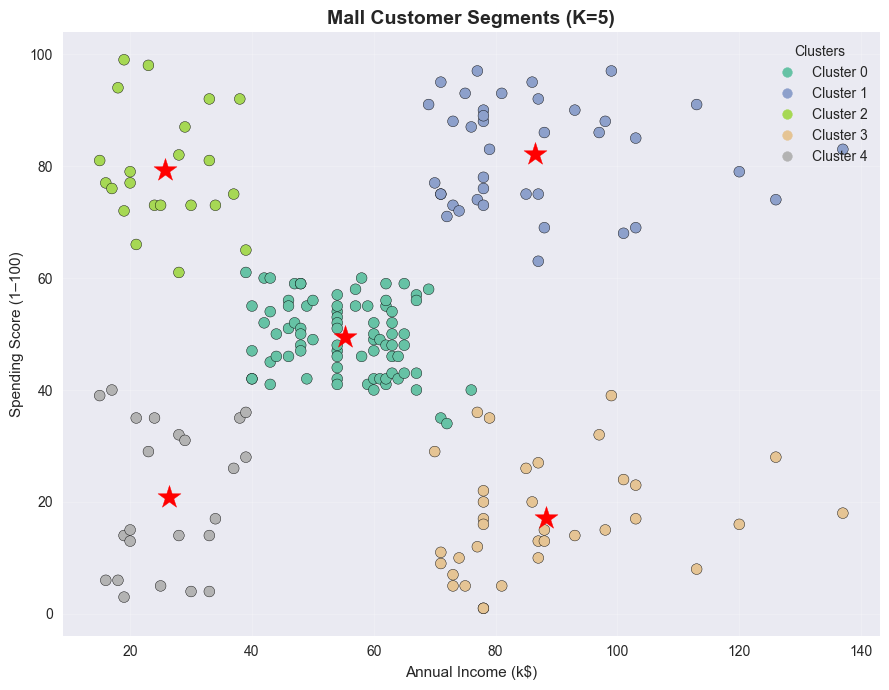

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043


In [18]:
# ── TASK 16 — Mall Customers: full clustering pipeline ───────────────────────
#
# Step 1: Load the dataset
url = 'https://gist.githubusercontent.com/pravalliyaram/5c05f43d2351249927b8a3f3cc3e5ecf/raw/Mall_Customers.csv'
mall = pd.read_csv(url)
print(f'Shape: {mall.shape}')
print(mall.head(3))

# Step 2: Extract the two features
X_mall = mall[['Annual Income (k$)', 'Spending Score (1-100)']].values


# Step 3: Run elbow method (K = 1 to 10), plot WCSS curve
mall_k_range = range(1, 11)
mall_wcss = []
for k in mall_k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_mall)
    mall_wcss.append(kmeans.inertia_)
    

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(mall_k_range), mall_wcss, marker='o', linestyle='-')
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('WCSS (Inertia)')
ax.set_title('Elbow Curve — Mall Customers')
ax.grid(alpha=0.3)
optimal_k = 5
ax.axvline(optimal_k, color='red', linestyle='--', label=f'Chosen K={optimal_k}')
ax.legend()
plt.tight_layout()
plt.show()

# Step 4: Train final KMeans with optimal K (from elbow)
for k, wcss in zip(mall_k_range, mall_wcss):
    print(f'K={k}  WCSS={wcss:.2f}')

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_final.fit(X_mall)
labels_final = kmeans_final.labels_
centroids_final = kmeans_final.cluster_centers_


# Step 5: Scatter plot — colour each point by cluster, mark centroids with stars
fig, ax = plt.subplots(figsize=(9, 7))
scatter = ax.scatter(
    X_mall[:, 0], X_mall[:, 1],
    c=labels_final, cmap='Set2', edgecolor='k', s=60
)
ax.scatter(
    centroids_final[:, 0], centroids_final[:, 1],
    marker='*', s=300, color='red', label='Centroids'
)

handles, _ = scatter.legend_elements()
ax.legend(handles, [f'Cluster {i}' for i in range(optimal_k)], title='Clusters', loc='upper right')
ax.set_title(f'Mall Customer Segments (K={optimal_k})', fontsize=14, fontweight='bold')
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1–100)')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Step 6: Interpret the clusters
mall_copy = mall.copy()
mall_copy['Cluster'] = labels_final
cluster_summary = mall_copy.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()
print(cluster_summary)

---
# 🍷 Lab 2 — Wine Classification: KNN vs SVM

## Dataset Overview

The Wine dataset contains chemical analyses of 178 wines from three cultivars in Italy.  
13 features — alcohol content, ash, flavonoids, colour intensity, and more.  
3 classes — three different wine types.

**Goal:** Build the best possible classifier and understand the impact of scaling and hyperparameter choices.

## Your Pipeline

```
Load → Split → Scale → KNN (K sweep) → SVM (C, gamma sweep) → Compare → Decision Boundaries
```

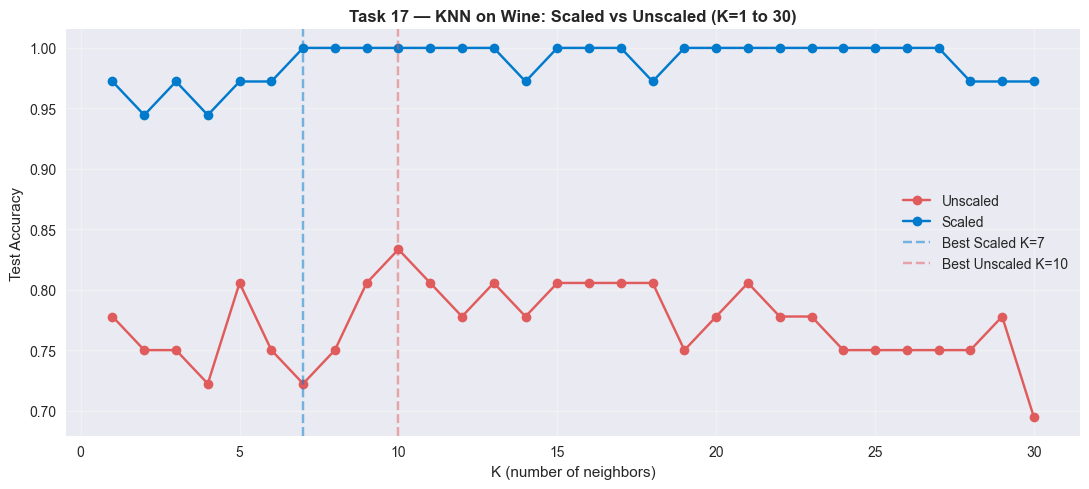

Best Unscaled: K=10  Acc=0.8333
Best  Scaled:  K=7   Acc=1.0000
Accuracy improvement (scaled - unscaled): 0.1667


In [19]:
# ── TASK 17 — KNN on Wine: K sweep with and without scaling ──────────────────
# The Wine dataset was already loaded above (load_wine)
# Plot K=1 to 30: scaled accuracy vs unscaled accuracy on the same axes
# Use the same train/test split from earlier (X_w_train, X_w_test)
# Print:
#   - Best K and accuracy without scaling
#   - Best K and accuracy with scaling
#   - Accuracy improvement

# NOTE: you already computed this in Task 8 — reuse if possible
# If not, recompute here

# YOUR CODE HERE
k_range_t17 = range(1, 31)
raw_accs_t17 = []
scaled_accs_t17 = []

for k in k_range_t17:
    knn_raw = KNeighborsClassifier(n_neighbors=k)
    knn_raw.fit(X_w_train, y_w_train)
    raw_accs_t17.append(accuracy_score(y_w_test, knn_raw.predict(X_w_test)))

    knn_sc = KNeighborsClassifier(n_neighbors=k)
    knn_sc.fit(X_w_train_sc, y_w_train)
    scaled_accs_t17.append(accuracy_score(y_w_test, knn_sc.predict(X_w_test_sc)))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(k_range_t17, raw_accs_t17,    marker='o', label='Unscaled', color='#e05c5c')
ax.plot(k_range_t17, scaled_accs_t17, marker='o', label='Scaled',   color='#007acc')

best_raw_k17_idx = int(np.argmax(raw_accs_t17))
best_sc_k17_idx  = int(np.argmax(scaled_accs_t17))
best_raw_k17     = list(k_range_t17)[best_raw_k17_idx]
best_sc_k17      = list(k_range_t17)[best_sc_k17_idx]
best_raw_acc_t17 = raw_accs_t17[best_raw_k17_idx]
best_sc_acc_t17  = scaled_accs_t17[best_sc_k17_idx]

ax.axvline(best_sc_k17, color='#007acc', linestyle='--', alpha=0.5,
           label=f'Best Scaled K={best_sc_k17}')
ax.axvline(best_raw_k17, color='#e05c5c', linestyle='--', alpha=0.5,
           label=f'Best Unscaled K={best_raw_k17}')

ax.set_xlabel('K (number of neighbors)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Task 17 — KNN on Wine: Scaled vs Unscaled (K=1 to 30)',
             fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Best Unscaled: K={best_raw_k17}  Acc={best_raw_acc_t17:.4f}')
print(f'Best  Scaled:  K={best_sc_k17}   Acc={best_sc_acc_t17:.4f}')
print(f'Accuracy improvement (scaled - unscaled): {best_sc_acc_t17 - best_raw_acc_t17:.4f}')

# 📝 How large is the accuracy gap at the best K?
# ...

Top 5 SVM configurations:
    C  gamma  accuracy
 10.0  0.001  1.000000
  1.0   0.01  1.000000
100.0    0.1  0.972222
100.0   0.01  0.972222
  0.1  scale  0.972222


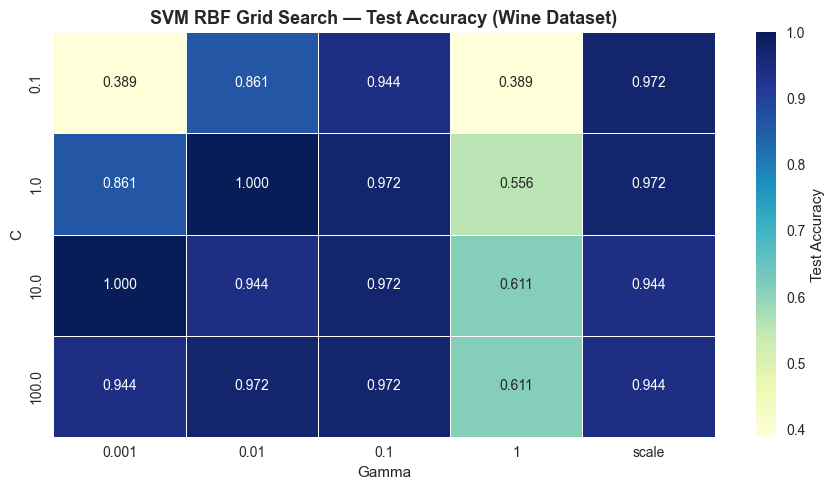


Best configuration: C=10.0, gamma=0.001, accuracy=1.0000

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [22]:
# ── TASK 18 — SVM RBF on Wine: tune C and gamma ──────────────────────────────
# Manual grid search over C and gamma
# C values:     [0.1, 1, 10, 100]
# gamma values: [0.001, 0.01, 0.1, 1, 'scale']
#
# For each combination, record test accuracy
# Print the top 5 combinations
# Train the best model and print its classification report

c_grid     = [0.1, 1, 10, 100]
gamma_grid = [0.001, 0.01, 0.1, 1, 'scale']

svm_results = []

# YOUR CODE HERE
for c in c_grid:
    for gamma in gamma_grid:
        svm = SVC(kernel='rbf', C=c, gamma=gamma)
        svm.fit(X_w_train_sc, y_w_train)
        acc = accuracy_score(y_w_test, svm.predict(X_w_test_sc))
        svm_results.append({'C': c, 'gamma': gamma, 'accuracy': acc})


svm_results_df = pd.DataFrame(svm_results).sort_values('accuracy', ascending=False)
print('Top 5 SVM configurations:')
print(svm_results_df.head(5).to_string(index=False))

# Heatmap of accuracy across C and gamma
pivot_gamma = [str(g) for g in gamma_grid]
pivot_data = svm_results_df.copy()
pivot_data['gamma'] = pivot_data['gamma'].astype(str)
heatmap_data = pivot_data.pivot(index='C', columns='gamma', values='accuracy')
# reorder columns to match gamma_grid order
heatmap_data = heatmap_data[[str(g) for g in gamma_grid]]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlGnBu',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Test Accuracy'})
ax.set_title('SVM RBF Grid Search — Test Accuracy (Wine Dataset)',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Gamma')
ax.set_ylabel('C')
plt.tight_layout()
plt.show()
# Train best model
best_svm_row = svm_results_df.iloc[0]
# YOUR CODE HERE — train best model, print classification report
best_c     = best_svm_row['C']
best_gamma = best_svm_row['gamma']

best_svm = SVC(kernel='rbf', C=best_c, gamma=best_gamma)
best_svm.fit(X_w_train_sc, y_w_train)
y_pred_best = best_svm.predict(X_w_test_sc)

print(f'\nBest configuration: C={best_c}, gamma={best_gamma}, '
      f'accuracy={best_svm_row["accuracy"]:.4f}')
print('\nClassification Report:')
print(classification_report(y_w_test, y_pred_best,
                             target_names=wine.target_names))


# 📝 What C and gamma combination works best?
# Does a very large C always give the best result?
# ...

=== FINAL MODEL COMPARISON ===
                  Accuracy  Precision  Recall   F1
Model                                             
KNN (scaled)           1.0        1.0     1.0  1.0
SVM RBF (scaled)       1.0        1.0     1.0  1.0


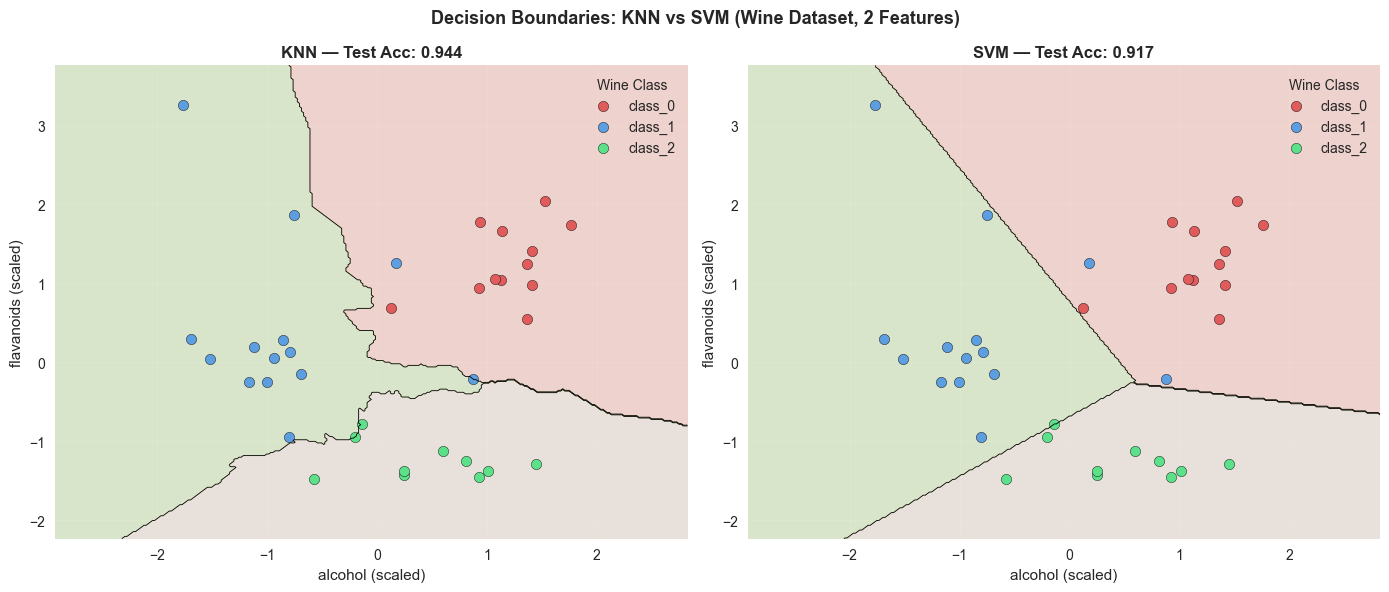

In [30]:
# ── TASK 19 — Full comparison: KNN vs SVM + decision boundaries ──────────────
#
# Part A: Metric comparison table
# Train both models with their best hyperparameters
# Build a DataFrame with columns: Accuracy, Precision, Recall, F1
# Use average='weighted' for multi-class metrics

best_k = best_sc_k17       # from Task 17 — set this

final_models = {
    'KNN (scaled)': KNeighborsClassifier(n_neighbors=best_k),
    'SVM RBF (scaled)': SVC(kernel='rbf', C=best_c, gamma=best_gamma),   # from Task 18
}
metric_rows = []
for name, model in final_models.items():
    # YOUR CODE HERE
    model.fit(X_w_train_sc, y_w_train)
    y_pred = model.predict(X_w_test_sc)
    metric_rows.append({
        'Model':     name,
        'Accuracy':  accuracy_score(y_w_test, y_pred),
        'Precision': precision_score(y_w_test, y_pred, average='weighted'),
        'Recall':    recall_score(y_w_test, y_pred, average='weighted'),
        'F1':        f1_score(y_w_test, y_pred, average='weighted'),
    })

print('=== FINAL MODEL COMPARISON ===')
print(pd.DataFrame(metric_rows).set_index('Model').round(3).to_string())

# Part B: Decision boundary visualisation (2 features)
# Use features: Alcohol (index 0) and Flavanoids (index 6)
# Create 1×2 subplots — KNN boundary left, SVM boundary right
# Use all three wine classes

feat_idx  = [0, 6]
feat_labels = [wine.feature_names[i] for i in feat_idx]

X_2f = X_wine[:, feat_idx]
X_2f_tr, X_2f_te, y_2f_tr, y_2f_te = train_test_split(
    X_2f, y_wine, test_size=0.2, stratify=y_wine, random_state=42
)
sc_2f = StandardScaler()
X_2f_tr_sc = sc_2f.fit_transform(X_2f_tr)
X_2f_te_sc = sc_2f.transform(X_2f_te)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# YOUR CODE HERE — decision boundaries for KNN and SVM on 2-feature Wine data
safe_k = min(best_k, len(X_2f_tr_sc) - 1)

all_2f = np.vstack([X_2f_tr_sc, X_2f_te_sc])
x_min, x_max = all_2f[:, 0].min() - 0.5, all_2f[:, 0].max() + 0.5
y_min, y_max = all_2f[:, 1].min() - 0.5, all_2f[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid_2f = np.c_[xx.ravel(), yy.ravel()]

boundary_models = {
    'KNN':  KNeighborsClassifier(n_neighbors=safe_k),
    'SVM':  SVC(kernel='rbf', C=best_c, gamma=best_gamma),
}

colors = ['#e05c5c', '#5c9ee0', '#5ce08a']

for ax, (label, model) in zip(axes, boundary_models.items()):
    model.fit(X_2f_tr_sc, y_2f_tr)
    acc = accuracy_score(y_2f_te, model.predict(X_2f_te_sc))

    Z = model.predict(grid_2f).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='Set2',
                levels=np.arange(Z.max() + 2) - 0.5)
    ax.contour(xx, yy, Z, colors='k', linewidths=0.6,
               levels=np.arange(Z.max() + 2) - 0.5)

    for cls, color in zip(np.unique(y_2f_te), colors):
        mask = y_2f_te == cls
        ax.scatter(X_2f_te_sc[mask, 0], X_2f_te_sc[mask, 1],
                   color=color, edgecolor='k', s=55,
                   label=wine.target_names[cls])

    ax.set_title(f'{label} — Test Acc: {acc:.3f}', fontweight='bold', fontsize=12)
    ax.set_xlabel(f'{feat_labels[0]} (scaled)')
    ax.set_ylabel(f'{feat_labels[1]} (scaled)')
    ax.legend(title='Wine Class', loc='upper right')
    ax.grid(alpha=0.2)

plt.suptitle('Decision Boundaries: KNN vs SVM (Wine Dataset, 2 Features)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 Which model produces a smoother boundary?
# Which model would you deploy in production and why?
# ...

---
# 📝 Day 8 Summary

| Concept | Key Takeaway |
|---------|-------------|
| **Euclidean Distance** | Straight-line distance — affected by scale |
| **Manhattan Distance** | City-block distance — more robust to outliers |
| **Cosine Similarity** | Measures direction not magnitude — ideal for text/high-dim data |
| **Feature Scaling** | Always required before KNN and SVM — otherwise large features dominate |
| **KNN** | Store everything, predict by majority vote of K nearest neighbours |
| **Choosing K** | Small K = overfit, Large K = underfit — use cross-validation |
| **SVM** | Find the widest margin boundary — only support vectors matter |
| **Parameter C** | Large C = narrow margin + strict, Small C = wide margin + tolerant |
| **RBF Kernel** | Maps data to higher dimensions to separate non-linear classes |
| **Gamma** | Small = smooth boundary, Large = wiggly boundary |
| **K-Means** | Group points by minimising within-cluster distances |
| **Elbow Method** | Plot WCSS vs K — choose K at the point of diminishing returns |

---
# 🏠 Homework

1. Train KNN with K from 1 to 30 on a dataset of your choice. Plot accuracy vs K. Report the best K and explain why smaller or larger values underperform.

2. Train KNN on the same dataset with and without StandardScaler. How large is the accuracy gap? Which feature do you think was responsible for the scaling effect?

3. Train SVM with four different C values and four different gamma values. Build a heatmap of test accuracy with C on one axis and gamma on the other. Identify the best combination.

4. Apply K-Means to a dataset of your choice. Use the Elbow Method to choose K. Plot the final clusters with centroids marked.

5. In your own words (3–5 sentences each): explain the difference between supervised learning and clustering, and explain why cosine similarity is preferred over Euclidean distance for comparing text documents.

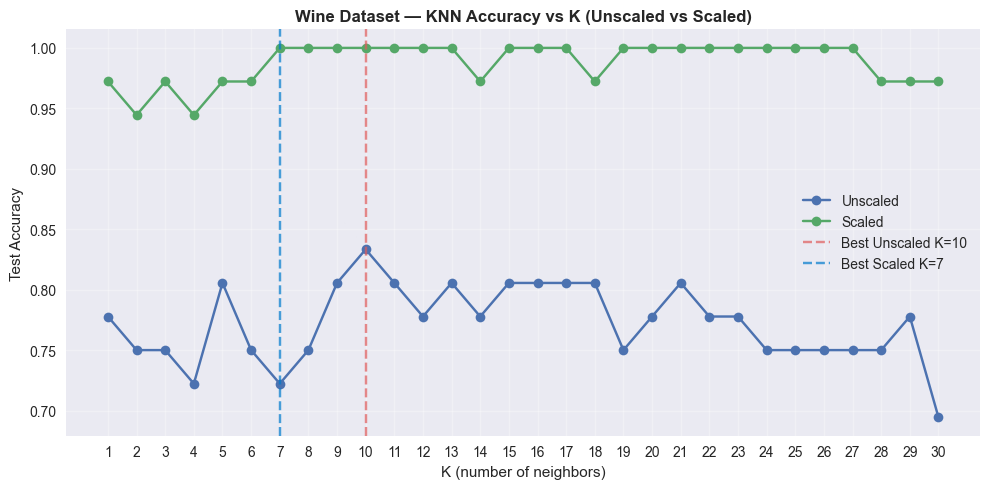

KNN on Wine dataset:
  Best unscaled K = 10   → accuracy = 0.8333
  Best scaled   K = 7   → accuracy = 1.0000
  Accuracy gap (scaled - unscaled) = 0.1667

Top 3 Wine features by raw numeric range:
  proline: range ≈ 1402.0
  magnesium: range ≈ 92.0
  alcalinity_of_ash: range ≈ 19.4

Explanation:
  - Smaller K tends to overfit because predictions follow local noise and individual points.
  - Larger K tends to underfit because the classifier averages too many neighbours and smooths over real class structure.
  - Scaling helps because Wine features have very different ranges; proline has the largest raw range and can dominate Euclidean distance if left unscaled.


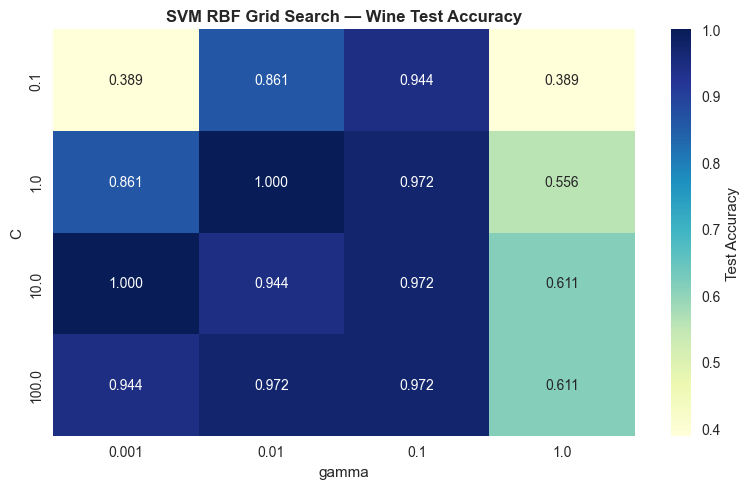

Best SVM configuration:
  C = 1, gamma = 0.01, accuracy = 1.0000


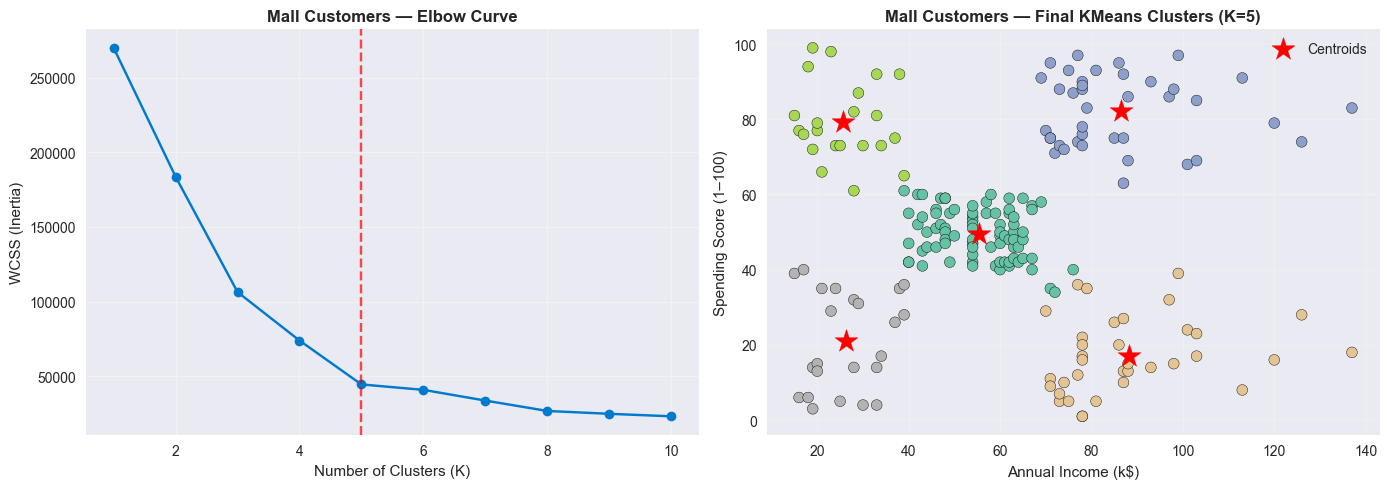

Mall Customers K-Means centroids:
  Cluster 0: income=55.3, spending=49.5
  Cluster 1: income=86.5, spending=82.1
  Cluster 2: income=25.7, spending=79.4
  Cluster 3: income=88.2, spending=17.1
  Cluster 4: income=26.3, spending=20.9

Supervised learning vs clustering:
  Supervised learning uses labeled examples to train a model that predicts target values for new data, while clustering is an unsupervised method that groups unlabeled data by similarity.
  In supervised learning, the goal is prediction against known labels; in clustering, the goal is discovery of natural structure without labels.

Why cosine similarity is preferred for text:
  Cosine similarity compares text vectors by their direction, so two documents with the same word proportions are treated as similar even if one is much longer.
  Euclidean distance, by contrast, is affected by magnitude and would consider a longer document farther away even when it shares the same semantic content.


In [31]:
# Task 1 & 2 — KNN on the Wine dataset
k_values = range(1, 31)
raw_accs = []
scaled_accs = []

for k in k_values:
    knn_raw = KNeighborsClassifier(n_neighbors=k)
    knn_raw.fit(X_w_train, y_w_train)
    raw_accs.append(accuracy_score(y_w_test, knn_raw.predict(X_w_test)))

    knn_sc = KNeighborsClassifier(n_neighbors=k)
    knn_sc.fit(X_w_train_sc, y_w_train)
    scaled_accs.append(accuracy_score(y_w_test, knn_sc.predict(X_w_test_sc)))

best_raw_idx = int(np.argmax(raw_accs))
best_scaled_idx = int(np.argmax(scaled_accs))
best_raw_k = k_values[best_raw_idx]
best_scaled_k = k_values[best_scaled_idx]
best_raw_acc = raw_accs[best_raw_idx]
best_scaled_acc = scaled_accs[best_scaled_idx]
accuracy_gap = best_scaled_acc - best_raw_acc

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_values, raw_accs, marker='o', label='Unscaled')
ax.plot(k_values, scaled_accs, marker='o', label='Scaled')
ax.axvline(best_raw_k, color='#e05c5c', linestyle='--', alpha=0.7,
           label=f'Best Unscaled K={best_raw_k}')
ax.axvline(best_scaled_k, color='#007acc', linestyle='--', alpha=0.7,
           label=f'Best Scaled K={best_scaled_k}')
ax.set_xlabel('K (number of neighbors)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Wine Dataset — KNN Accuracy vs K (Unscaled vs Scaled)', fontweight='bold')
ax.set_xticks(list(k_values))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('KNN on Wine dataset:')
print(f'  Best unscaled K = {best_raw_k}   → accuracy = {best_raw_acc:.4f}')
print(f'  Best scaled   K = {best_scaled_k}   → accuracy = {best_scaled_acc:.4f}')
print(f'  Accuracy gap (scaled - unscaled) = {accuracy_gap:.4f}\n')

feature_ranges = X_wine.max(axis=0) - X_wine.min(axis=0)
top_features = sorted(
    [(wine.feature_names[i], feature_ranges[i]) for i in range(len(feature_ranges))],
    key=lambda x: x[1],
    reverse=True
)[:3]
print('Top 3 Wine features by raw numeric range:')
for name, rng in top_features:
    print(f'  {name}: range ≈ {rng:.1f}')

print('\nExplanation:')
print('  - Smaller K tends to overfit because predictions follow local noise and individual points.')
print('  - Larger K tends to underfit because the classifier averages too many neighbours and smooths over real class structure.')
print('  - Scaling helps because Wine features have very different ranges; proline has the largest raw range and can dominate Euclidean distance if left unscaled.')

# Task 3 — SVM grid search on Wine dataset
c_grid = [0.1, 1, 10, 100]
gamma_grid = [0.001, 0.01, 0.1, 1]
svm_grid_results = []

for c in c_grid:
    for gamma in gamma_grid:
        svm = SVC(kernel='rbf', C=c, gamma=gamma)
        svm.fit(X_w_train_sc, y_w_train)
        acc = accuracy_score(y_w_test, svm.predict(X_w_test_sc))
        svm_grid_results.append({'C': c, 'gamma': gamma, 'accuracy': acc})

svm_df = pd.DataFrame(svm_grid_results).pivot(index='C', columns='gamma', values='accuracy')
best_svm_entry = max(svm_grid_results, key=lambda r: r['accuracy'])

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(svm_df, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax,
            cbar_kws={'label': 'Test Accuracy'})
ax.set_title('SVM RBF Grid Search — Wine Test Accuracy', fontweight='bold')
ax.set_xlabel('gamma')
ax.set_ylabel('C')
plt.tight_layout()
plt.show()

print('Best SVM configuration:')
print(f'  C = {best_svm_entry["C"]}, gamma = {best_svm_entry["gamma"]}, '
      f'accuracy = {best_svm_entry["accuracy"]:.4f}')

# Task 4 — K-Means clustering on the Mall Customers dataset
mall_k_range = range(1, 11)
mall_wcss = []

for k in mall_k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_mall)
    mall_wcss.append(kmeans.inertia_)

elbow_k = 5
kmeans_final = KMeans(n_clusters=elbow_k, random_state=42)
kmeans_final.fit(X_mall)
mall_labels = kmeans_final.labels_
mall_centroids = kmeans_final.cluster_centers_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(mall_k_range), mall_wcss, marker='o', color='#007acc')
axes[0].axvline(elbow_k, color='red', linestyle='--', alpha=0.7)
axes[0].set_title('Mall Customers — Elbow Curve', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('WCSS (Inertia)')
axes[0].grid(alpha=0.3)

scatter = axes[1].scatter(
    X_mall[:, 0], X_mall[:, 1],
    c=mall_labels, cmap='Set2', edgecolor='k', s=60
)
axes[1].scatter(mall_centroids[:, 0], mall_centroids[:, 1],
                marker='*', s=300, color='red', label='Centroids')
axes[1].set_title(f'Mall Customers — Final KMeans Clusters (K={elbow_k})', fontweight='bold')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1–100)')
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print('Mall Customers K-Means centroids:')
for i, centroid in enumerate(mall_centroids):
    print(f'  Cluster {i}: income={centroid[0]:.1f}, spending={centroid[1]:.1f}')

# Task 5 — Written answers
print('\nSupervised learning vs clustering:')
print('  Supervised learning uses labeled examples to train a model that predicts target values for new data, while clustering is an unsupervised method that groups unlabeled data by similarity.')
print('  In supervised learning, the goal is prediction against known labels; in clustering, the goal is discovery of natural structure without labels.')

print('\nWhy cosine similarity is preferred for text:')
print('  Cosine similarity compares text vectors by their direction, so two documents with the same word proportions are treated as similar even if one is much longer.')
print('  Euclidean distance, by contrast, is affected by magnitude and would consider a longer document farther away even when it shares the same semantic content.')